In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, iirnotch, find_peaks
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping


In [2]:
def preprocess_emg_signal(file_path, fs = 1000, mvc_dict=None):
    df = pd.read_csv(file_path)
    df_processed = df.copy()
    channels = [f'channel{i}' for i in range(1, 9)]
    nyq = 0.5 * fs
    b_band, a_band = butter(4, [20/nyq, 450/nyq], btype='band')
    b_low, a_low = butter(4, 10/nyq, btype='low')

    for ch in channels:
        if ch not in df.columns:
            print(f"Warning: cannot find {ch} in the file!")
            continue
        raw_sig = df[ch].fillna(0).values
        filtered = filtfilt(b_band, a_band, raw_sig)
        rectified = np.abs(filtered)
        envelope = filtfilt(b_low, a_low, rectified)
        envelope = np.maximum(envelope, 0)
        df_processed[ch] = envelope 
    for ch in channels:
        df_processed[ch] = df_processed.groupby('label')[ch].transform(
            lambda x: (x / (x.max() if x.max() > 0 else 1)) * 100
        )

        print(df_processed)

    output_file = file_path.replace('.csv', '_processed.csv')
    df_processed.to_csv(output_file, index=False)

    print("Finishing Preprocessing dataset")

    return df_processed


In [3]:
file_path = r"datasets\train\EMG-data.csv"
df = preprocess_emg_signal(file_path)
df 

          time  channel1  channel2      channel3  channel4  channel5  \
0            1  0.505663  0.000003  0.000000e+00  0.000004  0.000000   
1            5  0.540232  0.000003  4.408627e-07  0.000005  0.000000   
2            6  0.574307  0.000004  1.715085e-06  0.000006  0.000000   
3            7  0.607811  0.000005  2.980392e-06  0.000007  0.000000   
4            8  0.640667  0.000005  4.234796e-06  0.000008  0.000000   
...        ...       ...       ...           ...       ...       ...   
4237902  50962  1.788038  0.000005  7.649281e-06  0.000008  0.000035   
4237903  50963  1.784848  0.000005  7.643663e-06  0.000008  0.000035   
4237904  50964  1.782188  0.000005  7.638959e-06  0.000008  0.000035   
4237905  50965  1.780000  0.000005  7.635074e-06  0.000008  0.000035   
4237906  50966  1.778226  0.000005  7.631911e-06  0.000008  0.000035   

             channel6      channel7      channel8  class  label  
0        4.586132e-07  1.549889e-07  0.000000e+00      0      1  
1  

,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class,label
0,1,0.505663,0.426684,0.000000,0.569724,0.000000,0.098621,0.035534,0.000000,0,1
1,5,0.540232,0.521757,0.077848,0.747488,0.000000,0.207517,0.066253,0.000000,0,1
2,6,0.574307,0.618733,0.302852,0.923943,0.000000,0.314503,0.097629,0.000000,0,1
3,7,0.607811,0.717485,0.526282,1.098786,0.000000,0.419383,0.129625,0.000000,0,1
4,8,0.640667,0.817878,0.747786,1.271718,0.000000,0.521969,0.162198,0.008943,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4237902,50962,1.788038,1.957604,4.085815,1.574949,5.676281,4.573566,3.862965,4.831329,0,36
4237903,50963,1.784848,1.957495,4.082814,1.576233,5.682195,4.571260,3.867166,4.830561,0,36
4237904,50964,1.782188,1.957413,4.080302,1.577300,5.687095,4.569356,3.870658,4.829887,0,36
4237905,50965,1.780000,1.957352,4.078227,1.578175,5.691099,4.567802,3.873519,4.829305,0,36


In [4]:
def create_sliding_windows(data, window_size, step_size, channels):
    X, y = [], []
    for (subj, cls_val), group in data.groupby(['label', 'class']):
        group_vals = group[channels].values

        for i in range(0, len(group_vals) - window_size + 1, step_size):
            window = group_vals[i : i + window_size]
            X.append(window)
            y.append(cls_val)
            
    return np.array(X), np.array(y)

In [5]:
def prepare_emg_data_for_cnn(csv_file, window_size=200, step_size=50):
    df = pd.read_csv(csv_file)
    df = df[df['class'] != 0]
    df['class'] = df['class'] - 1

    train_subjects = list(range(1, 31))
    test_subjects = list(range(31, 37))

    train_df = df[df['label'].isin(train_subjects)]
    test_df = df[df['label'].isin(test_subjects)]

    channels = [f'channel{i}' for i in range(1, 9)]

    print("Slicing Training set")
    X_train, y_train = create_sliding_windows(train_df, window_size, step_size, channels)

    print("Slicing Testing set")
    X_test, y_test = create_sliding_windows(test_df, window_size, step_size, channels)

    print(f"X_train shape: {X_train.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"X_test shape:  {X_test.shape}")
    print(f"y_test shape:  {y_test.shape}")

    return X_train, y_train, X_test, y_test

X_train, y_train, X_test, y_test = prepare_emg_data_for_cnn('datasets/train/EMG-data_processed.csv', window_size=200, step_size=50)

Slicing Training set
Slicing Testing set
X_train shape: (24726, 200, 8)
y_train shape: (24726,)
X_test shape:  (4769, 200, 8)
y_test shape:  (4769,)


In [6]:
def build_and_train_cnn(X_train, y_train, X_test, y_test, num_classes=7):
    input_shape = (X_train.shape[1], X_train.shape[2])
    model = Sequential([
        Conv1D(filters=32, kernel_size=3, kernel_regularizer=tf.keras.regularizers.l2(1e-4), activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Conv1D(filters=64, kernel_size=3, kernel_regularizer=tf.keras.regularizers.l2(1e-4), activation='relu'),
        BatchNormalization(),
        MaxPooling1D(pool_size=2),

        Flatten(),
        Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])

    custom_optimizer = Adam(
        learning_rate=0.0005,
        beta_1=0.9,
        beta_2=0.999,
        epsilon=1e-7
    )
    model.compile(optimizer=custom_optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])
    callbacks = [
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    ]



    print("============== Model Summary: ==============")
    model.summary()

    print("Starting Training......")

    history = model.fit(X_train, y_train, 
                        epochs=50,       
                        batch_size=64,      
                        validation_data=(X_test, y_test),
                        callbacks=callbacks
               )
    
    test_loss, test_acc = model.evaluate(X_test, y_test)
    print(f"Test accuracy: {test_acc * 100:.2f}%")
    
    return model, history

model, history = build_and_train_cnn(X_train, y_train, X_test, y_test, num_classes=7)

c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


============== Model Summary: ==============


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 198, 32)        │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 198, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 97, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 97, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       393,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 401,639 (1.53 MB)

 Trainable params: 401,447 (1.53 MB)

 Non-trainable params: 192 (768.00 B)

Starting Training......
Epoch 1/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 29s 54ms/step - accuracy: 0.7497 - loss: 0.8238 - val_accuracy: 0.8658 - val_loss: 0.3782 - learning_rate: 5.0000e-04
Epoch 2/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - accuracy: 0.8472 - loss: 0.4514 - val_accuracy: 0.8981 - val_loss: 0.2899 - learning_rate: 5.0000e-04
Epoch 3/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8704 - loss: 0.3734 - val_accuracy: 0.8863 - val_loss: 0.3262 - learning_rate: 5.0000e-04
Epoch 4/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8742 - loss: 0.3574 - val_accuracy: 0.8939 - val_loss: 0.3070 - learning_rate: 5.0000e-04
Epoch 5/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8839 - loss: 0.3323 - val_accuracy: 0.9038 - val_loss: 0.2886 - learning_rate: 5.0000e-04
Epoch 6/50
387/387 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8973 - loss: 0.3090 - val_accuracy: 0.8985 - val_loss: 0.2993 - learning_rate: 5.0000e-04
Epoch 7/50
387/387 ━━━━━━━━━━━━━

### 3 Channel Dataset

In [7]:
import os
import glob
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, BatchNormalization, Dense, Dropout, Add, Activation, Bidirectional, LSTM
from tensorflow.keras.models import Model

def butter_bandpass(lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = max(lowcut / nyq, 0.001)
    high = min(highcut / nyq, 0.999)
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    cut = min(cutoff / nyq, 0.999)
    b, a = butter(order, cut, btype='low')
    return b, a

def preprocess_emg_signal(df, fs=1000):

    df_processed = df.copy()
    channels = [f'Channel {i}' for i in range(1, 4)]
    b_band, a_band = butter_bandpass(20, 450, fs, order=4)
    b_low, a_low = butter_lowpass(10, fs, order=4)
    b_notch, a_notch = iirnotch(w0=50, Q=30, fs=fs)

    for ch in channels:
        if ch not in df.columns:
            continue
        raw_sig = df[ch].fillna(0).values.astype(np.float32)
       
        sig_notch = filtfilt(b_notch, a_notch, raw_sig)
      
        filtered = filtfilt(b_band, a_band, sig_notch)
        
        rectified = np.abs(filtered)
      
        envelope = filtfilt(b_low, a_low, rectified)
        envelope = np.maximum(envelope, 0.0)
        df_processed[ch] = envelope

    return df_processed

def load_and_preprocess_dataset(base_dir="datasets/train", fs=1000):

    gesture_map = {
        '1st_Gesture_Resting': 0,
        '2nd_Gesture_Fist': 1,
        '4th_Gesture_Open_Hand': 2,
        '7th_Gesture_Pointing': 3
    }
    trials = []
    channels = ['Channel 1', 'Channel 2', 'Channel 3']
    
    for folder, cls_idx in gesture_map.items():
        files = sorted(glob.glob(os.path.join(base_dir, folder, "*.csv")))
        for f in files:
            df = pd.read_csv(f)
            df_proc = preprocess_emg_signal(df, fs=fs)
            trials.append({
                'file': os.path.basename(f),
                'signal': df_proc[channels].values,
                'class': cls_idx
            })
            
    print(f"Preprocessing finish: {len(trials)} trials ")
    return trials


In [8]:
trials = load_and_preprocess_dataset('datasets/train')


Preprocessing finish: 60 trials 


In [9]:
def create_sliding_windows(trials, window_size=200, step_size=25):
    X, y = [], []
    for t in trials:
        sig = t['signal']
        cls_val = t['class']
        for i in range(0, len(sig) - window_size + 1, step_size):
            X.append(sig[i : i + window_size])
            y.append(cls_val)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

train_trials, temp_trials = train_test_split(trials, test_size=0.3, random_state=42, stratify=[t['class'] for t in trials])
val_trials, test_trials = train_test_split(temp_trials, test_size=0.5, random_state=42, stratify=[t['class'] for t in temp_trials])

print(f"Trials Number: Train={len(train_trials)}, Val={len(val_trials)}, Test={len(test_trials)}")

X_train, y_train = create_sliding_windows(train_trials, window_size=200, step_size=25)
X_val, y_val = create_sliding_windows(val_trials, window_size=200, step_size=25)
X_test, y_test = create_sliding_windows(test_trials, window_size=200, step_size=25)

mean = np.mean(X_train, axis=(0, 1), keepdims=True)
std = np.std(X_train, axis=(0, 1), keepdims=True) + 1e-8

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")


Trials Number: Train=42, Val=9, Test=9
X_train shape: (5586, 200, 3) | y_train shape: (5586,)
X_val shape:   (1197, 200, 3)   | y_val shape:   (1197,)
X_test shape:  (1197, 200, 3)  | y_test shape:  (1197,)


In [10]:
def build_improved_emg_model(input_shape=(200, 3), num_classes=4):

    inputs = Input(shape=input_shape)
    
  
    c1 = Conv1D(32, kernel_size=7, padding='same')(inputs)
    c1 = BatchNormalization()(c1)
    c1 = Activation('relu')(c1)
    c1 = MaxPooling1D(2)(c1)
    
    # Residual Block 1
    res1 = Conv1D(64, kernel_size=5, padding='same')(c1)
    res1 = BatchNormalization()(res1)
    res1 = Activation('relu')(res1)
    res1 = Conv1D(64, kernel_size=5, padding='same')(res1)
    res1 = BatchNormalization()(res1)
    shortcut1 = Conv1D(64, kernel_size=1, padding='same')(c1)
    shortcut1 = BatchNormalization()(shortcut1)
    x = Add()([res1, shortcut1])
    x = Activation('relu')(x)
    x = MaxPooling1D(2)(x)
    x = Dropout(0.2)(x)
    
    # Residual Block 2
    res2 = Conv1D(128, kernel_size=3, padding='same')(x)
    res2 = BatchNormalization()(res2)
    res2 = Activation('relu')(res2)
    res2 = Conv1D(128, kernel_size=3, padding='same')(res2)
    res2 = BatchNormalization()(res2)
    shortcut2 = Conv1D(128, kernel_size=1, padding='same')(x)
    shortcut2 = BatchNormalization()(shortcut2)
    x = Add()([res2, shortcut2])
    x = Activation('relu')(x)
    x = MaxPooling1D(2)(x)
    x = Dropout(0.3)(x)
    
    # Temporal Layer: BiLSTM
    x = Bidirectional(LSTM(64, return_sequences=False))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.4)(x)
    
    # Classifier Head
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=outputs, name="ResNet_BiLSTM_EMG_3Ch")
    return model

model_3ch = build_improved_emg_model(input_shape=(200, 3), num_classes=4)
model_3ch.summary()


Model: "ResNet_BiLSTM_EMG_3Ch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 200, 3)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 200, 32)   │        704 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 200, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 200, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 100, 32)   │          0 │ activation[0][0]  │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 100, 64)   │     10,304 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 100, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 100, 64)   │     20,544 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 100, 64)   │      2,112 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 100, 64)   │        256 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 100, 64)   │          0 │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 100, 64)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_3     │ (None, 50, 64)    │          0 │ activation_2[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 64)    │          0 │ max_pooling1d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 50, 128)   │     24,704 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 50, 128)   │        512 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 50, 128)   │          0 │ batch_normalizat

 Total params: 226,244 (883.77 KB)

 Trainable params: 224,772 (878.02 KB)

 Non-trainable params: 1,472 (5.75 KB)

In [11]:
model_3ch.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

callbacks = [
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
]

history_3ch = model_3ch.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model_3ch.evaluate(X_test, y_test, verbose=0)
print(f"\n>>> TEST SET ACCURACY: {test_acc * 100:.2f}% (Loss: {test_loss:.4f})")


Epoch 1/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 26s 92ms/step - accuracy: 0.7442 - loss: 0.7556 - val_accuracy: 0.5856 - val_loss: 0.8198 - learning_rate: 0.0010
Epoch 2/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.8840 - loss: 0.3529 - val_accuracy: 0.6207 - val_loss: 0.7276 - learning_rate: 0.0010
Epoch 3/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.8817 - loss: 0.3390 - val_accuracy: 0.9006 - val_loss: 0.3402 - learning_rate: 0.0010
Epoch 4/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.8956 - loss: 0.3149 - val_accuracy: 0.8697 - val_loss: 0.6000 - learning_rate: 0.0010
Epoch 5/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.8876 - loss: 0.3385 - val_accuracy: 0.8705 - val_loss: 0.6859 - learning_rate: 0.0010
Epoch 6/40
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.9054 - loss: 0.2821 - val_accuracy: 0.8713 - val_loss: 0.4684 - learning_rate: 0.0010
Epoch 7/40
87/88 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8998 - loss: 0.3039
Epoch 7

38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step

===== CLASSIFICATION REPORT=====
                precision    recall  f1-score   support

  Resting (G1)     0.9778    0.9950    0.9863       399
     Fist (G2)     0.7027    0.8797    0.7813       266
Open Hand (G4)     1.0000    0.5489    0.7087       266
 Pointing (G7)     0.8205    0.9624    0.8858       266

      accuracy                         0.8630      1197
     macro avg     0.8753    0.8465    0.8405      1197
  weighted avg     0.8867    0.8630    0.8567      1197



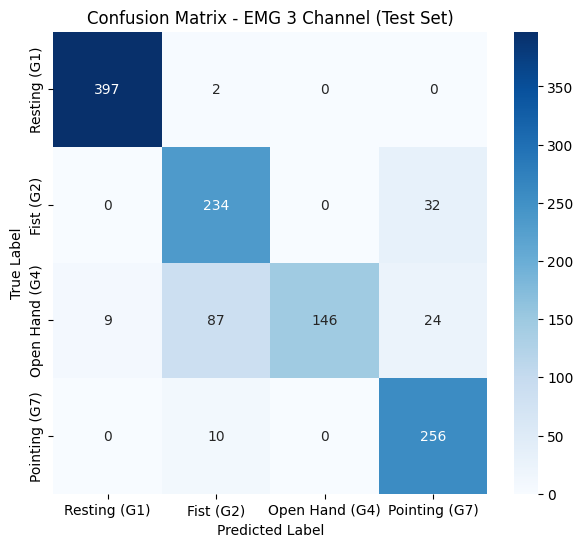

In [12]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_3ch_model(model, X_test, y_test):
    y_pred_probs = model.predict(X_test)
    y_pred = np.argmax(y_pred_probs, axis=1)
    target_names = ['Resting (G1)', 'Fist (G2)', 'Open Hand (G4)', 'Pointing (G7)']

    print("\n===== CLASSIFICATION REPORT=====")
    print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=target_names, yticklabels=target_names)
    plt.title('Confusion Matrix - EMG 3 Channel (Test Set)')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()

evaluate_3ch_model(model_3ch, X_test, y_test)
